# Crop-Type Classification from Sentinel-1 and Sentinel-2

**Technical notebook for the tech team.** Season: Rabi 2022-23, Maharashtra. Ground truth: surveyed farm polygons.

This notebook documents exactly how the project works: the data, how Google Earth Engine is used, how the features and crop signatures are built, which models are trained, the results, and the known limits.

**How to read it**

- Every table and chart is computed by the code cell above it, from the files the pipeline wrote (`data/features/`, `outputs/`).
- The notebook does not call Earth Engine and does not retrain models, so it runs in about a minute. The one optional live Earth Engine cell is switched off by default.
- To regenerate everything from scratch, run `python run.py` in the project folder first (section 2).

## Summary

| item | value |
|---|---|
| Task | Predict the crop grown in a field from its satellite time series |
| Classes | 10: Wheat, Gram, Onion, Sorghum, Maize, Cotton, Sugarcane, Soybean, Brinjal, Other |
| Fields used | 5,188 (3,584 train, 1,604 test), split per field |
| Satellite data | Sentinel-2 L2A (12 bands, 6 indices) and Sentinel-1 GRD (VV, VH, 2 derived) |
| Time series | 1 Sep 2022 to 29 Apr 2023, 24 composites of 10 days |
| Data source | Google Earth Engine, server-side processing, only numbers downloaded |
| Final model | Average of three models: field XGBoost, pixel TempCNN, pixel XGBoost |
| Test accuracy | **0.630** (macro F1 0.516, kappa 0.561) |
| Accuracy at confidence 0.8 or higher | **0.833**, covering 40% of test fields |
| Main limit | Survey labels are unverified; 17% of fields contradict their label (section 13) |
| Second limit | Radar is missing for about half of the field-dates; no ascending passes exist to fill it (section 6) |

## 1. Pipeline at a glance

| step | what happens | code | output |
|---|---|---|---|
| 1. Labels | Read the farm shapefile, keep one season, drop unusable rows, group rare crops | `src/croptype/labels.py` | `data/interim/labels.gpkg` |
| 2. Sampling | Build the area to read for each field, two ways (polygon, GPS point) | `src/croptype/geometry.py` | `data/interim/samples_*.gpkg` |
| 3. Earth Engine | Build 24 cloud-free composites and read them per field and per pixel | `src/croptype/gee_extract.py` | `data/features/signature_table_*.csv`, `pixels_polygon.npz` |
| 4. Features | Fill cloud gaps, one row per field, add growth-curve summary features | `src/croptype/dataset.py` | in memory |
| 5. Signatures | Median curve per crop, and how separable the crops are | `src/croptype/signatures.py` | `outputs/<mode>/signatures.*`, `separability.csv` |
| 6. Field models | Signature matching, Random Forest, XGBoost for both sampling approaches | `src/croptype/train.py` | `outputs/polygon/`, `outputs/point/` |
| 7. Final model | Field XGBoost + pixel TempCNN + pixel XGBoost, averaged | `src/croptype/pixel_model.py`, `ensemble.py` | `outputs/final/` |
| 8. Label review | List fields whose satellite curve contradicts the surveyed crop | `ensemble.py: label_review` | `outputs/label_review.csv` |

`src/croptype/cli.py` runs steps 1 to 8 in order. All settings live in `config.yaml`.

## 2. How to run the project

**One-time setup**

1. `pip install -r requirements.txt`
2. Unzip `farm_boundaries_FINAL_Squares_27Oct_updated.zip` into `data/raw/`. The shapefile is not in git because it holds survey photo links and surveyor names.
3. Put a Google Cloud project id that has the Earth Engine API enabled in `config.yaml` under `gee.project`.
4. The first run opens a browser once for the Earth Engine sign-in.

**Commands**

| command | what it does | time |
|---|---|---|
| `python run.py` | Full pipeline, steps 1 to 8 | about 18 minutes on a laptop CPU; downloads are cached, so a re-run skips them |
| `python run.py predict new_fields.shp` | Classify new farm polygons with the saved final model | depends on field count |
| `python -m pytest tests` | 3 tests on synthetic data, no Earth Engine needed | under a minute |

**Where the time goes in a full run** (from `outputs/_run.log`): Earth Engine downloads take about 4 minutes in total; the rest is model training, mostly the two XGBoost comparisons and the pixel models.

In [1]:
# Setup: locate the project, load the config, import the pipeline modules.
import json, sys, warnings, logging, platform
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, geopandas as gpd
from croptype.config import load_config
from croptype.labels import load_fields
from croptype.geometry import polygon_samples, point_samples
from croptype.features import FEATURES, S2_BANDS, S1_BANDS, S1_DERIVED, INDICES
from croptype.gee_extract import periods, PIXEL_FEATURES
from croptype.dataset import gap_fill, to_wide, build_matrix
from croptype.pixel_model import pixel_features, TempCNNClassifier
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160, "display.max_columns", 30)

cfg = load_config(str(ROOT / "config.yaml"))
OUTP, FEAT = cfg.path("paths", "outputs"), cfg.path("paths", "features")

import sklearn, xgboost, torch, shapely, ee
print("python", platform.python_version())
for m in (np, pd, gpd, shapely, sklearn, xgboost, torch, ee):
    print(f"{m.__name__:<14}{m.__version__}")

python 3.12.10
numpy         2.5.0
pandas        2.2.3
geopandas     1.1.4
shapely       2.1.2
sklearn       1.9.0
xgboost       3.4.1
torch         2.13.0+cpu
ee            1.7.33


### Settings used for this run (`config.yaml`)

In [2]:
for section in ("data", "season_window", "sampling", "gee", "model", "pixel"):
    print(f"[{section}]")
    for k, v in dict(cfg[section]).items():
        print(f"  {k:<26}{v}")

[data]
  shapefile                 data/raw/farm_boundaries_FINAL_Squares_27Oct_updated.shp
  season                    Rabi 2022-23
  min_class_count           30
  other_policy              group
  exclude_crops             ['Home', 'Fallow Land', 'Other Crop', 'Vegetables']
  only_train_ok             True
  only_mono                 True
[season_window]
  start                     2022-09-01
  end                       2023-04-30
  step_days                 10
[sampling]
  polygon_inner_buffer_m    10
  polygon_mode              inner
  min_square_half_m         5
  point_square_half_m       15
  point_clip_to_polygon     True
[gee]
  project                   job-portal-464909
  scale                     10
  chunk_size                150
  workers                   6
  cloud_score_threshold     0.6
  s1_orbit_pass             DESCENDING
[model]
  random_state              42
  use_given_split           True
  test_size                 0.25
  spatial_cv                False
  xgb 

## 3. Ground-truth labels

**Source:** `data/raw/farm_boundaries_FINAL_Squares_27Oct_updated.shp`. One row per farm polygon, with the surveyed crop, season, survey GPS point, survey time, district, a ready-made `train` / `test` split, and quality flags.

**Filters applied, in order** (`labels.py: load_fields`):

1. **Season = Rabi 2022-23.** The satellite window must match the season the crop was seen in, and this season holds about 89% of all fields.
2. **`train_ok` is true.** Drops fields the boundary QC step flagged.
3. **Crop type = Mono.** Drops intercrop fields, which have no single correct label.
4. **Drop non-crop or vague labels:** Home, Fallow Land, Other Crop, Vegetables.
5. **Valid geometry only;** invalid polygons are repaired with `make_valid`.
6. **Rare crops become "Other".** A crop needs at least 30 training fields to keep its own class. The count uses the training split only, so the test set never influences the class list.

The split is the shapefile's own `split` column and is per field: no field is in both train and test.

In [3]:
raw = gpd.read_file(cfg.path("data", "shapefile"))
d = cfg.data
steps = [("raw shapefile", raw)]
s = raw[raw["season_yea"] == d["season"]];                 steps.append((f"season = {d['season']}", s))
s = s[s["train_ok"].astype(bool)];                        steps.append(("train_ok = True", s))
s = s[s["Crop Type"] == "Mono"];                          steps.append(("mono crop only", s))
s = s[~s["Crop Name"].isin(d["exclude_crops"])];          steps.append(("non-crop labels removed", s))
funnel = pd.DataFrame({"step": [n for n, _ in steps], "fields": [len(x) for _, x in steps]})
funnel["removed"] = -funnel["fields"].diff().fillna(0).astype(int)
display(funnel)

print("Fields per season in the raw file:")
display(raw["season_yea"].value_counts().to_frame("fields").T)

,step,fields,removed
0,raw shapefile,5910,0
1,season = Rabi 2022-23,5279,631
2,train_ok = True,5210,69
3,mono crop only,5210,0
4,non-crop labels removed,5188,22


Fields per season in the raw file:


season_yea,Rabi 2022-23,Kharif 2026,Summer 2023,Kharif 2024,Rabi 2024-25,Summer 2025,Kharif 2025,Rabi 2023-24,Kharif 2023
fields,5279,376,203,22,16,7,4,2,1


In [4]:
logging.getLogger("croptype").setLevel(logging.WARNING)
fields = load_fields(cfg)
labels = fields.drop(columns="geometry")
counts = (labels.groupby(["label", "split"]).size().unstack(fill_value=0)
          .assign(total=lambda t: t.sum(1)).sort_values("total", ascending=False))
display(counts)
print(f"{len(labels)} fields | train {counts['train'].sum()} | test {counts['test'].sum()} | "
      f"{labels['district'].nunique()} districts | {labels['village'].nunique()} villages")
print("crops grouped into 'Other':", sorted(labels.loc[labels.label == 'Other', 'crop'].unique()))
print(f"field area (ha): median {labels.area_ha.median():.2f}, "
      f"10th pct {labels.area_ha.quantile(.1):.2f}, 90th pct {labels.area_ha.quantile(.9):.2f}")

split,test,train,total
label,,,
Wheat,379,867,1246
Gram,331,716,1047
Onion,245,529,774
Sorghum,170,374,544
Maize,132,335,467
Other,128,262,390
Cotton,95,229,324
Sugarcane,83,190,273
Soybean,27,50,77


5188 fields | train 3584 | test 1604 | 9 districts | 771 villages
crops grouped into 'Other': ['Bajra', 'Bajra (Fodder)', 'Banana', 'Bitter Gourd', 'Bottle Gourd', 'Cabbage', 'Cauliflower', 'Chilli', 'Coriander', 'Cucumber', 'Dragon Fruit', 'Fenugreek', 'Garlic', 'Ginger', 'Grape', 'Groundnut', 'Indian Bean', 'Lemon', 'Maize (Fodder)', 'Mango', 'Nagli/Ragi', 'Okra', 'Papaya', 'Pomegranate', 'Potato', 'Pumpkin', 'Rose', 'Sesamum', 'Sorghum (Fodder)', 'Sponge Gourd', 'Sugarbeet', 'Sunflower', 'Tobacco', 'Tomato', 'Tur', 'Turmeric', 'Watermelon']
field area (ha): median 0.40, 10th pct 0.10, 90th pct 1.17


**Label quality as recorded in the shapefile.** This matters for section 13: the survey's own status and quality columns show how many of the labels we train and test on were verified.

In [5]:
used = raw[raw["field_id"].astype(str).isin(labels["field_id"].astype(str))]
display(pd.concat({"Status": used["Status"].value_counts(dropna=False),
                   "Quality Ty": used["Quality Ty"].value_counts(dropna=False),
                   "boundary source": used["boundary_s"].value_counts(dropna=False)}).to_frame("fields"))

fields
Status          Pending       5188
Quality Ty      Non-QC        5188
boundary source digitised     4996
                square_30m     192

## 4. Sampling geometry: which pixels represent a field

Sentinel pixels are 10 m. Pixels on a field's edge mix the crop with bunds, roads and the neighbour's field, so we do not read the raw polygon. Two approaches are built and compared (`geometry.py`). All metric work is done in the local UTM zone and converted back to EPSG:4326 for Earth Engine.

**Approach 1, polygon (used by the final model)**

- Shrink the polygon inwards by 10 m (`polygon_inner_buffer_m`), which removes about one pixel of edge.
- If the shrunk shape is empty or smaller than one pixel (100 m²), keep the raw polygon and flag it `no_buffer_small_field`.
- `polygon_mode: inner` uses the whole shrunk polygon. `polygon_mode: square` instead takes the largest square inside it (side from the maximum inscribed circle, radius / √2). We tested both; `inner` gives about three times more pixels per field and scored higher, so it is the default.

**Approach 2, GPS point**

- A 30 m × 30 m square (3 × 3 pixels) centred on the surveyor's GPS point.
- Clipped to the farm polygon when the point is inside it, so the square does not spill into the neighbour's field.
- Fields whose GPS point is outside the polygon are flagged.

In [6]:
sm = cfg.sampling
samples = {"polygon": polygon_samples(fields, sm["polygon_inner_buffer_m"], sm["polygon_mode"], sm["min_square_half_m"]),
           "point": point_samples(fields, sm["point_square_half_m"], sm["point_clip_to_polygon"])}
for mode, g in samples.items():
    print(f"--- {mode}: pixels per field: median {g.approx_pixels.median():.1f}, "
          f"10th pct {g.approx_pixels.quantile(.1):.1f}, 90th pct {g.approx_pixels.quantile(.9):.1f}")
    display(g["geom_method"].value_counts().to_frame("fields"))

--- polygon: pixels per field: median 16.9, 10th pct 3.5, 90th pct 73.0


,fields
geom_method,
inner_buffer,4525
no_buffer_small_field,663


--- point: pixels per field: median 8.4, 10th pct 5.0, 90th pct 9.0


,fields
geom_method,
point_square_clipped,5166
point_square_point_outside_polygon,20
point_square,2


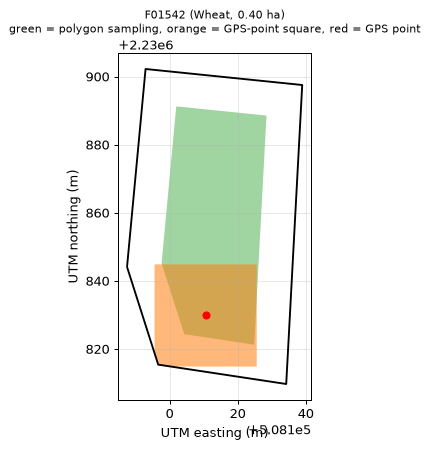

In [7]:
# One example field: raw polygon, inner-buffered polygon (approach 1), GPS square (approach 2).
utm = fields.estimate_utm_crs()
ex = labels.index[(labels.area_ha - labels.area_ha.median()).abs().argmin()]
fid = labels.loc[ex, "field_id"]
fig, ax = plt.subplots(figsize=(5, 5))
fields.loc[[ex]].to_crs(utm).boundary.plot(ax=ax, color="black", lw=1.5, label="farm polygon")
samples["polygon"].loc[[ex]].to_crs(utm).plot(ax=ax, color="tab:green", alpha=.45)
samples["point"].loc[[ex]].to_crs(utm).plot(ax=ax, color="tab:orange", alpha=.55)
gpd.GeoSeries(gpd.points_from_xy([labels.loc[ex, "lon"]], [labels.loc[ex, "lat"]]), crs=4326).to_crs(utm).plot(
    ax=ax, color="red", markersize=30)
ax.set_title(f"{fid} ({labels.loc[ex,'label']}, {labels.loc[ex,'area_ha']:.2f} ha)\n"
             "green = polygon sampling, orange = GPS-point square, red = GPS point", fontsize=9)
ax.set_xlabel("UTM easting (m)"); ax.set_ylabel("UTM northing (m)"); ax.set_aspect("equal")
plt.show()

## 5. Google Earth Engine: what we use it for and how

**Yes, the project uses Google Earth Engine** (Python client `earthengine-api`). It is the only source of satellite data.

**Key design choice:** no imagery is downloaded. All image processing (cloud masking, compositing, index calculation, per-field statistics) runs on Google's servers. The laptop only receives tables of numbers. That is why 5,188 fields × 24 dates × 22 features arrive in about a minute.

### 5.1 Access

| item | detail |
|---|---|
| Client | `earthengine-api`, imported as `ee` |
| Start-up | `ee.Initialize(project=cfg.gee.project)`; if no saved credentials exist it calls `ee.Authenticate()` (browser sign-in, once per machine) |
| Project | Google Cloud project with the Earth Engine API enabled, set in `config.yaml` (`gee.project`) |
| Request type | Synchronous `getInfo()` calls; no export tasks, no Cloud Storage |
| If sign-in has expired | Earth Engine raises "Please authorize access"; run `earthengine authenticate` once in a terminal and retry |

### 5.2 Datasets

| dataset | Earth Engine id | used for |
|---|---|---|
| Sentinel-2 surface reflectance (L2A) | `COPERNICUS/S2_SR_HARMONIZED` | 12 optical bands and 6 indices |
| Cloud Score+ | `GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED` | cloud and shadow mask for Sentinel-2 |
| Sentinel-1 radar (GRD) | `COPERNICUS/S1_GRD` | VV and VH backscatter, which see through cloud |

### 5.3 Sentinel-2 processing (`s2_collection`, `add_indices`)

1. Filter the collection to the request's bounding box and the 10-day period.
2. Join each image to its Cloud Score+ image (`linkCollection`, band `cs_cdf`).
3. Keep the 12 L2A bands (B1 to B9, B8A, B11, B12) and divide by 10,000 to get reflectance on a 0 to 1 scale. L2A has no B10, and B13 to B15 do not exist on Sentinel-2.
4. Compute the six indices **per image, before compositing**:

| index | formula |
|---|---|
| NDVI | (B8 − B4) / (B8 + B4) |
| EVI | 2.5 (B8 − B4) / (B8 + 6·B4 − 7.5·B2 + 1) |
| NDMI | (B8 − B11) / (B8 + B11) |
| NDRE | (B8 − B5) / (B8 + B5) |
| SAVI | 1.5 (B8 − B4) / (B8 + B4 + 0.5) |
| GNDVI | (B8 − B3) / (B8 + B3) |

5. Mask every pixel with `cs_cdf < 0.60` (`cloud_score_threshold`). Higher is stricter.
6. Take the per-pixel **median** of all remaining images in the period.

### 5.4 Sentinel-1 processing (`s1_collection`)

1. Filter: IW mode, both VV and VH present, **descending** orbit only (`s1_orbit_pass`). One orbit direction keeps the viewing angle consistent across dates.
2. Mask values below −30 dB (border noise and no-data).
3. Convert dB to linear power, take the **mean** over the period, convert back to dB. Averaging in dB would bias the result low.
4. Derive two more features: `VH_VV = 10·log10(VH / VV)` and the radar vegetation index `RVI = 4·VH / (VV + VH)` (linear units).

**Coverage caveat:** only Sentinel-1A was flying in this season (Sentinel-1B stopped working in December 2021), so a given track repeats every 12 days. With 10-day periods and one orbit direction, many periods have no radar pass. Section 6 measures the gap; it is large.

### 5.5 From composites to one stacked image (`period_composite`, `build_stack`)

- Each period gives one image with 22 bands: 6 indices, VV, VH, VH_VV, RVI and 12 optical bands.
- The 24 period images are concatenated into **one image** with bands named `<feature>_tNN` (for example `NDVI_t07`): 24 × 22 = 528 bands.
- A fully masked placeholder image is merged into each period's collection, so a period with no usable image still produces all bands (masked) and the band list stays fixed.
- Every image is cast with `.toFloat()`. Without it Earth Engine rejects the merged collection ("Expected a homogeneous image collection"), because raw band types differ.

### 5.6 Reading values per field (`_reduce_chunk`, `extract`)

- **Call:** `stack.reduceRegions(collection, reducer=median + count, scale=10, tileScale=4)`.
- **Result per field and date:** the median of each feature over the field's pixels, plus the count of valid pixels (`n_valid_s2`, `n_valid_s1`).
- **Chunking:** 150 fields per request (`chunk_size`). Fields are sorted by location first so each request covers a small area.
- **Output:** `data/features/signature_table_<mode>.csv`, one row per field and date.

### 5.7 Reading values per pixel (`extract_pixels`)

- **Call:** `stack.unmask(-9999).sampleRegions(collection, scale=10, tileScale=4)`. It returns one record per 10 m pixel in each field.
- `unmask(-9999)` is needed because `sampleRegions` drops any pixel that has a masked band; −9999 is turned back into NaN locally.
- Only the 14 raw bands are requested (12 optical, VV, VH): 24 × 14 = 336 bands. Indices are recomputed locally from them, which keeps responses small.
- **Chunking by pixel count:** each request is kept under 3,500 pixels because Earth Engine returns at most 5,000 records per response.
- **Output:** `data/features/pixels_polygon.npz` holding `X[pixel, date, band]` as float32, plus `field_id`, `bands`, `dates`.

### 5.8 Reliability and speed (`_run_chunks`, `_cache_dir`)

| mechanism | detail |
|---|---|
| Parallel requests | 6 at a time (`gee.workers`), using a thread pool |
| Cache | Each finished chunk is saved to `data/features/_chunks_<name>_<hash>/`. An interrupted run resumes; a re-run downloads nothing |
| Cache key | 8-character MD5 of the season window, cloud threshold, orbit, scale and field count. Changing any of these in `config.yaml` creates a new cache folder, so stale data is never reused |
| Retries | Only transient errors (timeout, quota, 429, 502, 503, memory limit) are retried, up to 4 times with waits of 10, 20, 40, 80 s |
| Fail fast | A non-transient error (a bug in the request) stops immediately |
| No partial data | If any chunk still fails, the run raises an error and does not write the table. Training never sees a table with fields silently missing |

**Measured in the last full run** (`outputs/_run.log`):

| download | requests | time |
|---|---|---|
| Field table, polygon sampling | 35 | about 40 s |
| Field table, point sampling | 35 | about 75 s |
| Pixel time series, polygon sampling | 47 | about 90 s |

In [8]:
# The 24 composite periods. A final period shorter than half a step is dropped
# (a 1-day stub would be almost always empty).
w = cfg.season_window
per = periods(w["start"], w["end"], w["step_days"])
pt = pd.DataFrame({"t": range(len(per)), "start": [a.date() for a, _ in per], "end": [b.date() for _, b in per]})
display(pt.T)
print(f"{len(per)} periods x {len(FEATURES)} features = {len(per) * len(FEATURES)} bands in the field stack")
print("features:", FEATURES)
print(f"pixel stack: {len(per)} x {len(PIXEL_FEATURES)} = {len(per) * len(PIXEL_FEATURES)} bands")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
t,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
start,2022-09-01,2022-09-11,2022-09-21,2022-10-01,2022-10-11,2022-10-21,2022-10-31,2022-11-10,2022-11-20,2022-11-30,2022-12-10,2022-12-20,2022-12-30,2023-01-09,2023-01-19,2023-01-29,2023-02-08,2023-02-18,2023-02-28,2023-03-10,2023-03-20,2023-03-30,2023-04-09,2023-04-19
end,2022-09-11,2022-09-21,2022-10-01,2022-10-11,2022-10-21,2022-10-31,2022-11-10,2022-11-20,2022-11-30,2022-12-10,2022-12-20,2022-12-30,2023-01-09,2023-01-19,2023-01-29,2023-02-08,2023-02-18,2023-02-28,2023-03-10,2023-03-20,2023-03-30,2023-04-09,2023-04-19,2023-04-29


24 periods x 22 features = 528 bands in the field stack
features: ['NDVI', 'EVI', 'NDMI', 'NDRE', 'SAVI', 'GNDVI', 'VV', 'VH', 'VH_VV', 'RVI', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']
pixel stack: 24 x 14 = 336 bands


**Optional live check.** Set `RUN_EE = True` to pull the signature table for three fields straight from Earth Engine (needs the sign-in and the project id). It writes to a temporary folder and does not touch the project's cache.

In [9]:
RUN_EE = False
if RUN_EE:
    import tempfile
    from croptype import gee_extract
    gee_extract.initialize(cfg.gee["project"])
    demo = gee_extract.extract(samples["polygon"].head(3), cfg, Path(tempfile.mkdtemp()) / "demo.csv")
    display(demo[["field_id", "t", "date", "NDVI", "EVI", "VV", "VH", "n_valid_s2", "n_valid_s1"]].head(8))
else:
    print("skipped (RUN_EE = False)")

skipped (RUN_EE = False)


## 6. The signature table (rows and columns)

This is the raw result of the Earth Engine step: **one row per field and date**, with one column per feature. It is the table to open when you want to inspect a field's season.

In [10]:
long = {m: pd.read_csv(FEAT / f"signature_table_{m}.csv") for m in ("polygon", "point")}
lp = long["polygon"]
print("polygon table:", lp.shape, "=", lp.field_id.nunique(), "fields x", lp.t.nunique(), "dates")
print("columns:", list(lp.columns))
display(lp[lp.field_id == fid][["field_id", "t", "date", "NDVI", "EVI", "NDMI", "VV", "VH", "B4", "B8",
                                "n_valid_s2", "n_valid_s1"]].head(8).round(3))

polygon table: (124512, 28) = 5188 fields x 24 dates
columns: ['field_id', 'sample_mode', 't', 'date', 'NDVI', 'EVI', 'NDMI', 'NDRE', 'SAVI', 'GNDVI', 'VV', 'VH', 'VH_VV', 'RVI', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'n_valid_s2', 'n_valid_s1']


,field_id,t,date,NDVI,EVI,NDMI,VV,VH,B4,B8,n_valid_s2,n_valid_s1
72042,F01542,0,2022-09-06,0.649,0.401,0.175,NaN,NaN,0.058,0.272,30,0
72192,F01542,1,2022-09-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
72342,F01542,2,2022-09-26,0.298,0.146,0.139,NaN,NaN,0.070,0.131,30,0
72492,F01542,3,2022-10-06,0.323,0.140,-0.095,NaN,NaN,0.078,0.150,30,0
72642,F01542,4,2022-10-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0
72792,F01542,5,2022-10-26,0.497,0.258,0.079,NaN,NaN,0.065,0.191,30,0
72942,F01542,6,2022-11-05,0.511,0.279,0.096,NaN,NaN,0.067,0.207,30,0
73092,F01542,7,2022-11-15,0.571,0.325,0.117,NaN,NaN,0.064,0.233,30,0


**Missing data per date.** A field has no Sentinel-2 value for a period when every image in those 10 days was cloudy over it. A field has no Sentinel-1 value when no descending radar pass covered it in those 10 days.

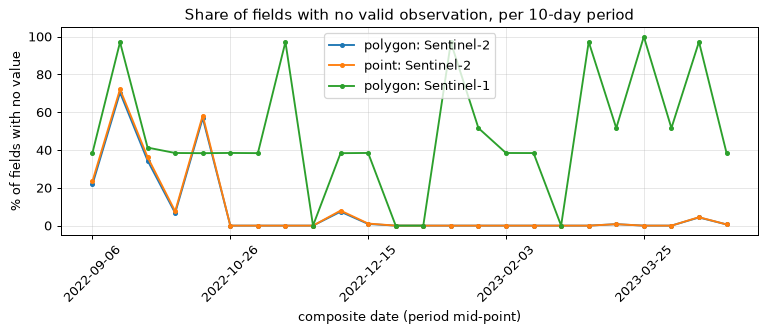

overall missing: Sentinel-2 8.5%, Sentinel-1 48.6% (polygon table)


In [11]:
miss = pd.DataFrame({f"{m}: Sentinel-2": t.groupby("date")["NDVI"].apply(lambda s: s.isna().mean())
                     for m, t in long.items()})
miss["polygon: Sentinel-1"] = lp.groupby("date")["VV"].apply(lambda s: s.isna().mean())
ax = (miss * 100).plot(figsize=(10, 3), marker="o", ms=3)
ax.set_ylabel("% of fields with no value"); ax.set_xlabel("composite date (period mid-point)")
ax.set_title("Share of fields with no valid observation, per 10-day period"); plt.xticks(rotation=45); plt.show()
print(f"overall missing: Sentinel-2 {lp.NDVI.isna().mean():.1%}, Sentinel-1 {lp.VV.isna().mean():.1%} (polygon table)")

In [12]:
# Radar coverage per district: how many of the 24 periods have a Sentinel-1 value.
s1 = lp.assign(has_s1=lp["VV"].notna()).merge(labels[["field_id", "district"]], on="field_id")
per_field = s1.groupby(["district", "field_id"])["has_s1"].sum()
cov_s1 = per_field.groupby("district").agg(fields="size", median_periods_with_radar="median").sort_values("fields", ascending=False)
cov_s1["share of the 24 periods"] = (cov_s1["median_periods_with_radar"] / 24).round(2)
display(cov_s1)

,fields,median_periods_with_radar,share of the 24 periods
district,,,
Buldana,1746,15.0,0.62
Aurangabad,1461,7.0,0.29
Osmanabad,1175,15.0,0.62
Nashik,761,7.0,0.29
Jalna,22,18.0,0.75
Latur,10,15.0,0.62
Washim,9,15.0,0.62
Hingoli,2,15.0,0.62
Solapur,2,15.0,0.62


**Reading this**

- **Sentinel-2:** fewer than one in ten field-dates is missing. Interpolation handles this well.
- **Sentinel-1: about half of all field-dates have no radar value**, and the gap depends on the district because each district sits under a different descending track. In the worst districts a field has radar in only about a quarter of the periods.
- **Consequence:** the radar features (VV, VH, VH_VV, RVI) are largely interpolated values. They still carry signal, but much less than 24 dates suggest, and the interpolation pattern differs by district.
- **Tested fix that does not work:** `gee.s1_orbit_pass: BOTH` was run end to end. The radar values and the gaps came back identical (48.6% missing in both runs), which means Sentinel-1 made no ascending passes over these districts in this season. The gap cannot be closed with this setting, so the config stays on `DESCENDING`.
- **Not yet tested:** a wider radar window (for example the nearest pass within 12 days of each period) would fill the gaps in the better-covered districts. It would not help much in Aurangabad and Nashik, where the passes themselves are sparse.

## 7. From the signature table to model features (`dataset.py`)

1. **Drop fields with too little data:** a field missing Sentinel-2 on more than 50% of dates is removed.
2. **Gap-fill:** each feature of each field is linearly interpolated over time; gaps at the start or end take the nearest value.
3. **Pivot to wide:** one row per field, one column per feature and date (`NDVI_t00` … `B12_t23`): 22 × 24 = 528 columns.
4. **Add 12 growth-curve features** from the NDVI and VH curves:

| feature | meaning |
|---|---|
| `ph_ndvi_max`, `ph_ndvi_min`, `ph_ndvi_amp` | peak, lowest value, and their difference |
| `ph_t_peak` | period index of peak greenness |
| `ph_ndvi_auc` | sum of NDVI over the season |
| `ph_greenup_rate`, `ph_t_greenup` | steepest rise between two periods, and when |
| `ph_senescence_rate`, `ph_t_senescence` | steepest fall, and when |
| `ph_season_len` | number of periods above half the amplitude |
| `ph_vh_mean`, `ph_vh_std` | mean and spread of VH backscatter |

A crop's "unique signature" is this full vector: crops that look alike on one date differ in when they green up, how high they peak, and when they dry down.

In [13]:
table, feature_cols = build_matrix(lp, labels)
print("model table:", table.shape[0], "fields x", len(feature_cols), "feature columns")
print("fields dropped for >50% missing Sentinel-2:", lp.field_id.nunique() - table.field_id.nunique())
print("growth-curve features:", [c for c in feature_cols if c.startswith("ph_")])
display(table[["field_id", "label", "split", "NDVI_t00", "NDVI_t12", "VH_t12", "ph_ndvi_max", "ph_t_peak",
               "ph_season_len"]].head(5).round(3))

model table: 5188 fields x 540 feature columns
fields dropped for >50% missing Sentinel-2: 0
growth-curve features: ['ph_ndvi_max', 'ph_ndvi_min', 'ph_ndvi_amp', 'ph_t_peak', 'ph_ndvi_auc', 'ph_greenup_rate', 'ph_senescence_rate', 'ph_t_greenup', 'ph_t_senescence', 'ph_season_len', 'ph_vh_mean', 'ph_vh_std']


,field_id,label,split,NDVI_t00,NDVI_t12,VH_t12,ph_ndvi_max,ph_t_peak,ph_season_len
0,F00427,Wheat,train,0.812,0.775,-17.662,0.812,0,13
1,F00428,Wheat,train,0.698,0.421,-15.568,0.698,0,7
2,F00429,Wheat,train,0.758,0.266,-18.424,0.822,3,10
3,F00430,Onion,test,0.795,0.261,-19.677,0.795,0,7
4,F00431,Onion,test,0.741,0.259,-15.856,0.741,0,5


## 8. Crop signatures and separability (`signatures.py`)

- **Signature:** for each crop and date, the median of each feature over the crop's **training** fields. Saved as `outputs/<mode>/signatures.csv`, with the interquartile range in `signatures_iqr.csv`. Rows are (crop, date); columns are the 22 features.
- **Separability:** Jeffries–Matusita (JM) distance between every pair of crops, per feature, using the feature's full 24-date series. The scale is 0 to 2: above 1.9 the pair is well separated, below 1.0 it is poorly separated.

signatures.csv: (240, 26) | columns: ['label', 't', 'date', 'NDVI', 'EVI', 'NDMI', 'NDRE', 'SAVI'] ...


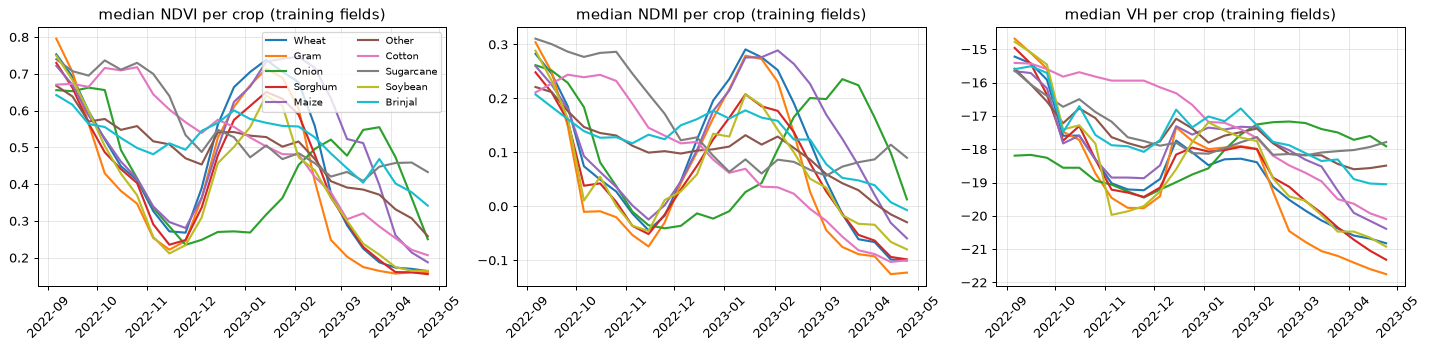

In [14]:
sig = pd.read_csv(OUTP / "polygon" / "signatures.csv", parse_dates=["date"])
print("signatures.csv:", sig.shape, "| columns:", list(sig.columns)[:8], "...")
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = sig.drop_duplicates("label").sort_values("n_fields", ascending=False)["label"]
for ax, f in zip(axes, ["NDVI", "NDMI", "VH"]):
    for i, lab in enumerate(order):
        s = sig[sig.label == lab]
        ax.plot(s.date, s[f], label=lab, color=plt.get_cmap("tab10")(i), lw=1.7)
    ax.set_title(f"median {f} per crop (training fields)"); ax.tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

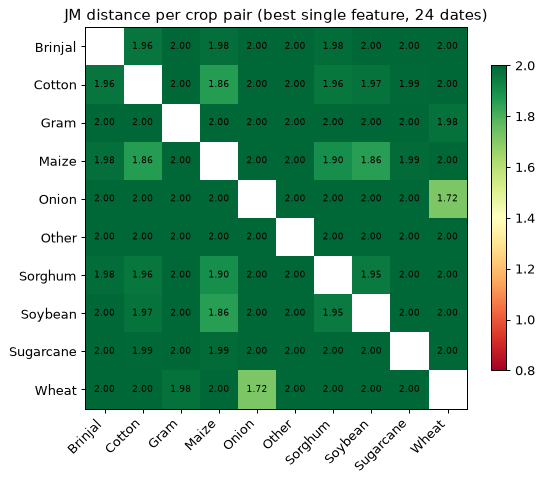

Hardest pairs to separate:


,,JM (best feature)
crop_a,crop_b,
Onion,Wheat,1.716
Maize,Soybean,1.855
Cotton,Maize,1.863
Maize,Sorghum,1.899
Sorghum,Soybean,1.950
Cotton,Sorghum,1.959


Mean JM per feature, top 8:


feature,VH,VH_VV,VV,RVI,B11,EVI,SAVI,B5
mean JM,1.947,1.941,1.938,1.908,1.683,1.683,1.667,1.666


In [15]:
jm = pd.read_csv(OUTP / "polygon" / "separability.csv")
best = jm.groupby(["crop_a", "crop_b"])["jm"].max()          # best single feature for each pair
labs = sorted(set(jm.crop_a) | set(jm.crop_b))
M = pd.DataFrame(np.nan, index=labs, columns=labs)
for (a, b), v in best.items():
    M.loc[a, b] = M.loc[b, a] = v
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(M.to_numpy(float), vmin=0.8, vmax=2, cmap="RdYlGn")
ax.set_xticks(range(len(labs)), labs, rotation=45, ha="right"); ax.set_yticks(range(len(labs)), labs); ax.grid(False)
for i in range(len(labs)):
    for j in range(len(labs)):
        if i != j and not np.isnan(M.iat[i, j]):
            ax.text(j, i, f"{M.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("JM distance per crop pair (best single feature, 24 dates)"); plt.colorbar(im, shrink=.8); plt.show()
print("Hardest pairs to separate:"); display(best.sort_values().head(6).round(3).to_frame("JM (best feature)"))
print("Mean JM per feature, top 8:"); display(jm.groupby("feature")["jm"].mean().sort_values(ascending=False).head(8).round(3).to_frame("mean JM").T)

**Reading this**

- JM assumes each crop is one Gaussian cloud, and with 24 dimensions per feature it is optimistic. Use it to rank crop pairs, not as a promise of accuracy.
- Onion and Wheat are the least separable pair, and they are among the pairs the models confuse most (section 12).
- **The high JM of the radar features is partly an artefact.** About half of the radar values are interpolated (section 6), which makes the series smoother and their covariance tighter than real data, and that inflates JM. The importance ranking from XGBoost (section 9) puts the optical red-edge and vegetation indices first.

## 9. Field-level models and the sampling comparison (`train.py`)

Three models are trained on the 540-column field table, once per sampling approach, and scored on the same 1,604 test fields.

| model | what it is | settings |
|---|---|---|
| `signature` | Nearest-signature baseline: standardise the features, take each crop's median vector, assign a field to the closest one | no tuning; fully transparent |
| `rf` | Random Forest | 500 trees, `min_samples_leaf=2`, `class_weight="balanced_subsample"` |
| `xgb` | XGBoost, `multi:softprob` | 800 trees, depth 6, learning rate 0.05, row subsample 0.8, column subsample 0.4, `hist` method, balanced sample weights |

- **Class imbalance:** Wheat has about 27 times more fields than Brinjal. Balanced weights make every class count equally in training. This is why macro F1 is reported next to accuracy.
- **Metrics:** accuracy, macro F1 (mean F1 over classes, so small classes count), weighted F1, Cohen's kappa.
- **Optional check:** `model.spatial_cv: true` adds 5-fold cross-validation grouped by village, which estimates accuracy on villages never seen in training. It is off by default because it adds about 10 minutes.

In [16]:
rows = []
for mode in ("polygon", "point"):
    for name, r in json.loads((OUTP / mode / "metrics.json").read_text()).items():
        if "accuracy" in r:
            rows.append({"sampling": mode, "model": name, **r})
cmp = pd.DataFrame(rows).pivot(index="model", columns="sampling", values=["accuracy", "macro_f1", "kappa"])
display(cmp.loc[["signature", "rf", "xgb"]])

accuracy         macro_f1           kappa        
sampling     point polygon    point polygon   point polygon
model                                                      
signature   0.4202  0.4177   0.3441  0.3342  0.3365  0.3335
rf          0.5873  0.5779   0.4436  0.4455  0.5097  0.4990
xgb         0.6278  0.6209   0.5018  0.5206  0.5591  0.5506

**Reading this**

- XGBoost is the strongest field-level model under both approaches.
- The two sampling approaches differ by less than one point of accuracy, which is within noise for 1,604 test fields. Polygon sampling has the higher macro F1.
- The final model uses **polygon** sampling for two reasons: new fields arrive as boundaries without GPS points, and the polygon gives more pixels per field for the pixel models.

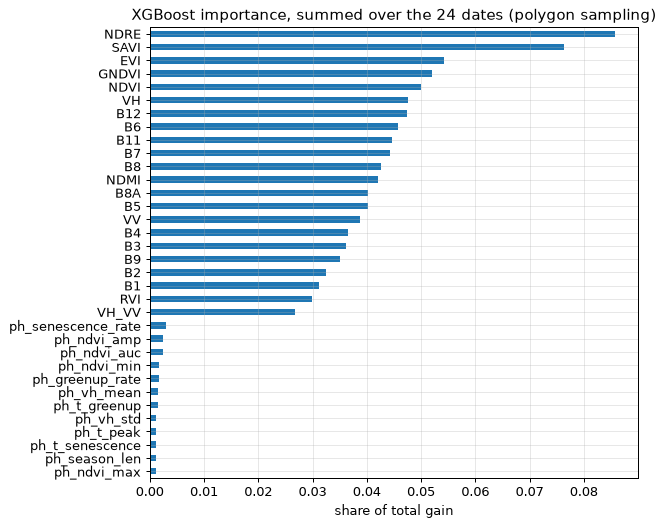

In [17]:
imp = pd.read_csv(OUTP / "polygon" / "importance_by_feature.csv", index_col=0)["importance"]
ax = imp.sort_values().plot.barh(figsize=(7, 6.5), color="tab:blue")
ax.set_title("XGBoost importance, summed over the 24 dates (polygon sampling)"); ax.set_xlabel("share of total gain")
plt.show()

## 10. Pixel-level data and models (`pixel_model.py`)

**Idea:** a field median throws away the variation inside the field. Here every 10 m pixel is a training example with its own 24-date curve, and at prediction time the pixels of a field vote.

**Pixel features (`pixel_features`)**

- Input: `X[pixel, date, band]` with 14 bands (12 optical, VV, VH).
- Adds 7 indices computed locally: NDVI, EVI, NDMI, NDRE, SAVI, GNDVI, and `VH_VV` (VH − VV in dB).
- Values are clipped to ±50 to guard against division blow-ups, then gaps are linearly interpolated over time (`interpolate_time`).
- Output: `F[pixel, 21 features, 24 dates]`.

**Fair training set**

- A test field's pixels are never used in training: pixels inherit the split of their field.
- At most 64 random pixels per field (`max_pixels_per_field`), so a few large farms cannot dominate.
- Sample weights make every field count the same regardless of its pixel count, and every class count the same regardless of its field count (`sample_weights`).
- 10% of the training **fields** are held out as a validation set for early stopping.

**Model A, TempCNN (`TempCNNClassifier`)**

- A 1-D convolutional network over the time axis, the standard deep-learning baseline for crop time series (Pelletier et al., 2019).
- Layers: 3 × [Conv1d(kernel 5, 64 filters) → BatchNorm → ReLU → Dropout 0.3] → Flatten → Linear 256 → BatchNorm → ReLU → Dropout → Linear to 10 classes.
- A kernel of 5 dates spans about 50 days, so the filters learn shapes such as a rise, a peak or a fall.
- Inputs are standardised per feature using training-set mean and standard deviation.
- Training: PyTorch on CPU, AdamW (lr 1e-3, weight decay 1e-4), OneCycle learning-rate schedule (max 3e-3), batch 512, up to 40 epochs, Gaussian noise (σ 0.03) added to inputs as augmentation.
- Early stopping: stop after 6 epochs without a better validation accuracy and restore the best weights.

**Model B, pixel XGBoost**

- Same pixels, flattened to 21 × 24 = 504 columns.
- 500 trees, depth 8, learning rate 0.08, row subsample 0.7, column subsample 0.3, `max_bin=128`.

**Voting (`field_vote`):** the class probabilities of a field's pixels are averaged into one probability vector per field.

In [18]:
pix = np.load(FEAT / "pixels_polygon.npz", allow_pickle=False)
X, pfid = pix["X"], pix["field_id"]
print("X shape (pixels, dates, bands):", X.shape, X.dtype, "| bands:", [str(b) for b in pix["bands"]])
ppf = pd.Series(pfid).value_counts()
print(f"fields with at least one pixel: {len(ppf)} of {len(labels)} "
      f"({len(labels) - len(ppf)} fields are too small to contain a pixel centre)")
print(f"pixels per field: median {ppf.median():.0f}, 10th pct {ppf.quantile(.1):.0f}, 90th pct {ppf.quantile(.9):.0f}, max {ppf.max()}")
print(f"missing optical values (cloud): {np.isnan(X[:, :, 0]).mean():.1%} | missing radar values: {np.isnan(X[:, :, -1]).mean():.1%}")

net = TempCNNClassifier()._net(21, X.shape[1], labels.label.nunique())
print(f"\nTempCNN trainable parameters: {sum(p.numel() for p in net.parameters()):,}")
print(net)

X shape (pixels, dates, bands): (170941, 24, 14) float32 | bands: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'VV', 'VH']
fields with at least one pixel: 5152 of 5188 (36 fields are too small to contain a pixel centre)
pixels per field: median 18, 10th pct 4, 90th pct 78, max 535
missing optical values (cloud): 9.2% | missing radar values: 44.5%

TempCNN trainable parameters: 444,810
Sequential(
  (0): Conv1d(21, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Conv1d(64, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True

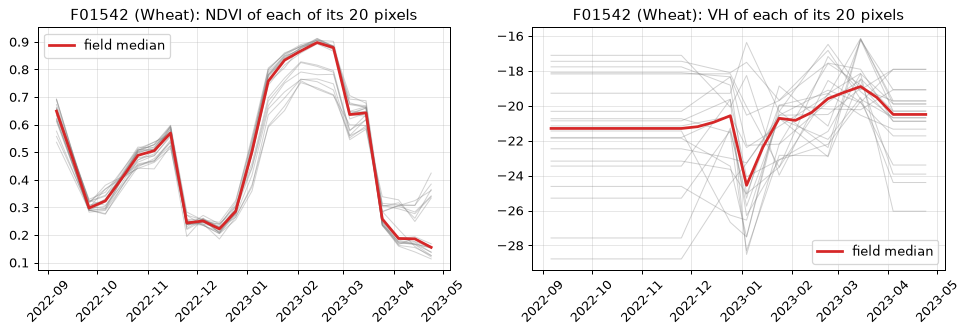

In [19]:
# Pixel curves of the example field against the field median the field-level model sees.
k = pfid == fid
F, names = pixel_features(X[k], list(pix["bands"]))
dates = pd.to_datetime(pix["dates"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, f in zip(axes, ["NDVI", "VH"]):
    j = names.index(f)
    ax.plot(dates, F[:, j, :].T, color="gray", alpha=.35, lw=.8)
    ax.plot(dates, np.median(F[:, j, :], 0), color="tab:red", lw=2.2, label="field median")
    ax.set_title(f"{fid} ({labels.set_index('field_id').loc[fid, 'label']}): {f} of each of its {k.sum()} pixels")
    ax.legend(); ax.tick_params(axis="x", rotation=45)
plt.show()

## 11. The final model: an ensemble of three (`ensemble.py`)

| member | input | model |
|---|---|---|
| `field` | 540 field-level features | XGBoost |
| `cnn` | 21 × 24 per pixel, pixels vote | TempCNN |
| `pxgb` | 504 per pixel, pixels vote | XGBoost |

- **Combination (`combine`):** a plain average of the three probability vectors per field. No weights are tuned, so nothing is fitted on the test set.
- **Small fields:** a field with no pixel has no vote from the two pixel members; the average is then taken over the members that did vote, which is the field model alone.
- **Prediction:** the crop with the highest averaged probability. That probability is reported as `confidence`.
- **Saved model:** `outputs/final/model.joblib` holds the three members, the class list, the field feature columns and the pixel band order. The TempCNN is stored as its weights plus its shape, so the file loads without special handling.

In [20]:
fm = json.loads((OUTP / "final" / "metrics.json").read_text())
res = pd.DataFrame({k: {m: v[m] for m in ("n_fields", "accuracy", "macro_f1", "kappa")} for k, v in fm.items()}).T
res.index = res.index.map({"field": "field XGBoost", "cnn": "pixel TempCNN", "pxgb": "pixel XGBoost",
                           "ensemble": "ENSEMBLE (final)"})
display(res)

,n_fields,accuracy,macro_f1,kappa
field XGBoost,1604.0,0.6209,0.5206,0.5506
pixel TempCNN,1590.0,0.6239,0.5238,0.5608
pixel XGBoost,1590.0,0.6082,0.4749,0.5326
ENSEMBLE (final),1604.0,0.6297,0.5156,0.5609


**Reading this:** each member alone scores between 0.61 and 0.62, and the average of the three is the best single number. The two pixel members are scored on slightly fewer fields because the smallest fields contain no pixel.

## 12. Results on the test fields

All numbers below are recomputed from `outputs/final/test_predictions.csv`, which holds the ensemble's probabilities, the surveyed label, the predicted crop and the confidence for each test field.

In [21]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, cohen_kappa_score
tp = pd.read_csv(OUTP / "final" / "test_predictions.csv", index_col=0)
y, p = tp["label"], tp["predicted"]
print(f"test fields {len(tp)} | accuracy {accuracy_score(y, p):.3f} | macro F1 {f1_score(y, p, average='macro'):.3f} "
      f"| kappa {cohen_kappa_score(y, p):.3f}\n")
print(classification_report(y, p, digits=3, zero_division=0))

test fields 1604 | accuracy 0.630 | macro F1 0.516 | kappa 0.561

              precision    recall  f1-score   support

     Brinjal      0.000     0.000     0.000        14
      Cotton      0.542     0.684     0.605        95
        Gram      0.630     0.740     0.681       331
       Maize      0.596     0.470     0.525       132
       Onion      0.753     0.710     0.731       245
       Other      0.545     0.430     0.480       128
     Sorghum      0.555     0.506     0.529       170
     Soybean      0.500     0.185     0.270        27
   Sugarcane      0.580     0.783     0.667        83
       Wheat      0.668     0.668     0.668       379

    accuracy                          0.630      1604
   macro avg      0.537     0.518     0.516      1604
weighted avg      0.625     0.630     0.622      1604



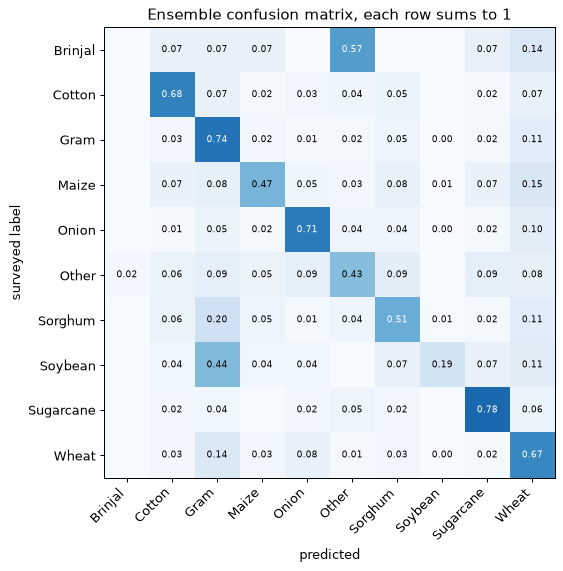

Largest confusions:


,surveyed,predicted,fields
0,Wheat,Gram,52
1,Gram,Wheat,36
2,Sorghum,Gram,34
3,Wheat,Onion,29
4,Onion,Wheat,25
5,Maize,Wheat,20
6,Sorghum,Wheat,18
7,Gram,Sorghum,16


In [22]:
cls = sorted(y.unique())
cm = confusion_matrix(y, p, labels=cls)
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cls)), cls, rotation=45, ha="right"); ax.set_yticks(range(len(cls)), cls)
for i in range(len(cls)):
    for j in range(len(cls)):
        if cm[i, j]:
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if cmn[i, j] > .5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("surveyed label"); ax.set_title("Ensemble confusion matrix, each row sums to 1")
plt.show()
off = pd.DataFrame(cm, index=cls, columns=cls).stack().rename("fields").reset_index()
off.columns = ["surveyed", "predicted", "fields"]
print("Largest confusions:")
display(off[off.surveyed != off.predicted].sort_values("fields", ascending=False).head(8).reset_index(drop=True))

### Confidence: which predictions can be used now

The confidence score sorts predictions well. Keeping only fields above a threshold trades coverage for accuracy.

,confidence >=,share of test fields,accuracy on those fields
0,0.00,1.000,0.630
1,0.40,0.873,0.683
2,0.50,0.769,0.710
3,0.60,0.645,0.751
4,0.70,0.534,0.786
5,0.80,0.403,0.833
6,0.85,0.316,0.860
7,0.90,0.218,0.862


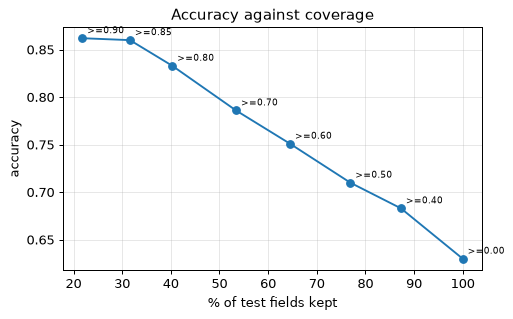

In [23]:
ok = (y == p).to_numpy(); conf = tp["confidence"].to_numpy()
thr = np.array([0, .4, .5, .6, .7, .8, .85, .9])
cov = pd.DataFrame({"confidence >=": thr,
                    "share of test fields": [(conf >= t).mean() for t in thr],
                    "accuracy on those fields": [ok[conf >= t].mean() for t in thr]}).round(3)
display(cov)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(cov["share of test fields"] * 100, cov["accuracy on those fields"], marker="o")
for _, r in cov.iterrows():
    ax.annotate(f">={r['confidence >=']:.2f}", (r["share of test fields"] * 100, r["accuracy on those fields"]),
                textcoords="offset points", xytext=(4, 4), fontsize=7)
ax.set_xlabel("% of test fields kept"); ax.set_ylabel("accuracy"); ax.set_title("Accuracy against coverage"); plt.show()

In [24]:
# Where the errors are: by boundary source, pixel count and district.
meta = labels.set_index("field_id").loc[tp.index]
e = pd.DataFrame({"correct": ok, "boundary_source": meta["boundary_source"].to_numpy(),
                  "district": meta["district"].to_numpy(),
                  "pixels": ppf.reindex(tp.index).fillna(0).to_numpy()})
e["pixels in field"] = pd.cut(e.pixels, [-1, 0, 5, 15, 40, 1e9], labels=["0", "1-5", "6-15", "16-40", ">40"])
for col in ("boundary_source", "pixels in field", "district"):
    display(e.groupby(col, observed=True)["correct"].agg(fields="size", accuracy="mean").round(3)
            .sort_values("fields", ascending=False).head(8))

,fields,accuracy
boundary_source,,
digitised,1546,0.638
square_30m,58,0.397


,fields,accuracy
pixels in field,,
16-40,467,0.623
6-15,437,0.629
>40,426,0.643
1-5,260,0.623
0,14,0.571


,fields,accuracy
district,,
Buldana,542,0.673
Aurangabad,416,0.584
Osmanabad,405,0.578
Nashik,227,0.700
Jalna,10,0.500
Washim,3,1.000
Hingoli,1,1.000


**Reading this**

- **Boundary source matters most.** Fields whose boundary is an automatic 30 m square (no digitised polygon) score far below digitised fields. They are few, but they are the weakest group.
- **Field size matters little.** Accuracy is similar from 1 to 5 pixels up to more than 40 pixels, so small fields are not the main source of error.
- **Districts differ.** Nashik and Buldana score highest; Aurangabad and Osmanabad are lower. Districts with only a handful of test fields are not meaningful.

## 13. Why accuracy stops near 63%: the labels

The target was 90% accuracy. The evidence below says the limit is the survey labels, not the model.

**How the review works (`label_review`)**

1. Train the field XGBoost with 5-fold cross-validation over **all** fields, so every field is scored by a model that never saw it.
2. Flag a field when the model gives its surveyed crop less than 10% probability **and** gives another crop more than 60%.
3. Write the flagged fields to `outputs/label_review.csv`, strongest disagreement first, with the survey photo link, surveyor and survey time so each one can be checked against its photo.

A flag is not proof that the label is wrong. It means the season's satellite curve looks like another crop, and the photo should decide.

In [25]:
lr = pd.read_csv(OUTP / "label_review.csv")
print(f"flagged fields: {len(lr)} of {len(labels)} ({len(lr) / len(labels):.1%})")
print("columns:", list(lr.columns))
bysplit = lr["split"].value_counts().to_frame("flagged")
bysplit["of fields in split"] = (bysplit["flagged"] / labels["split"].value_counts()).round(3)
display(bysplit)
pairs = lr.groupby(["surveyed_crop", "satellite_says"]).size().sort_values(ascending=False).head(10)
print("Most common disagreements (surveyed crop -> what the satellite curve looks like):")
display(pairs.to_frame("fields").reset_index())
rate = (lr["district"].value_counts() / labels["district"].value_counts()).dropna()
display(pd.DataFrame({"fields": labels["district"].value_counts(), "share flagged": rate.round(3)})
        .sort_values("fields", ascending=False).head(8))
display(lr[["field_id", "surveyed_crop", "satellite_says", "p_surveyed_crop", "p_satellite_crop", "split",
            "district", "crop_stage"]].head(8))

flagged fields: 884 of 5188 (17.0%)
columns: ['field_id', 'surveyed_crop', 'satellite_says', 'p_surveyed_crop', 'p_satellite_crop', 'split', 'village', 'district', 'crop_stage', 'surveyor', 'survey_time', 'image_url']


,flagged,of fields in split
split,,
train,601,0.168
test,283,0.176


Most common disagreements (surveyed crop -> what the satellite curve looks like):


,surveyed_crop,satellite_says,fields
0,Wheat,Gram,81
1,Gram,Wheat,63
2,Wheat,Onion,59
3,Sorghum,Gram,44
4,Maize,Wheat,37
5,Onion,Wheat,32
6,Gram,Sorghum,27
7,Maize,Gram,25
8,Sorghum,Wheat,25
9,Wheat,Sorghum,23


,fields,share flagged
district,,
Buldana,1746,0.174
Aurangabad,1461,0.168
Osmanabad,1175,0.192
Nashik,761,0.135
Jalna,22,0.182
Latur,10,NaN
Washim,9,0.111
Hingoli,2,NaN


,field_id,surveyed_crop,satellite_says,p_surveyed_crop,p_satellite_crop,split,district,crop_stage
0,F01074,Wheat,Onion,0.001,0.999,train,Nashik,Flowering Stage
1,F00854,Gram,Onion,0.000,0.999,train,Nashik,Flowering Stage
2,F02141,Onion,Cotton,0.000,0.999,train,Aurangabad,Flowering Stage
3,F01296,Wheat,Onion,0.000,0.999,train,Nashik,Branching Stage
4,F05037,Wheat,Sugarcane,0.000,0.999,train,Osmanabad,Fruit Formation Stage
5,F03658,Gram,Wheat,0.001,0.999,train,Buldana,Flowering Stage
6,F00537,Wheat,Onion,0.001,0.998,train,Nashik,Flowering Stage
7,F02298,Onion,Wheat,0.000,0.998,train,Aurangabad,Flowering Stage


In [26]:
# How much of the test error sits in flagged fields?
flag = tp.index.isin(lr["field_id"])
print(f"test fields flagged: {flag.sum()} of {len(tp)} ({flag.mean():.1%})")
print(f"accuracy on flagged test fields:     {ok[flag].mean():.3f}")
print(f"accuracy on non-flagged test fields: {ok[~flag].mean():.3f}")
print(f"share of all test errors that are flagged fields: {(~ok & flag).sum() / (~ok).sum():.1%}")

test fields flagged: 283 of 1604 (17.6%)
accuracy on flagged test fields:     0.007
accuracy on non-flagged test fields: 0.763
share of all test errors that are flagged fields: 47.3%


**How to read these numbers:** accuracy on flagged fields is close to zero by construction, because a field is flagged exactly when a model strongly disagrees with its label. The useful numbers are the other two: flagged fields account for about half of all test errors, and on the remaining test fields the model scores about 0.76. If the photo check confirms that most flagged labels are wrong, the true accuracy is well above the measured 0.63. That check has not been done yet.

**What the evidence says**

- **The labels are unverified.** The status and quality table in section 3 shows how the survey itself rates the labels used here.
- **About 17% of fields are flagged**, in train and test alike. Test accuracy is measured against these labels, so a model that is right about the crop is still marked wrong on those fields.
- **Different model families land in the same place.** A tree model on field medians, a tree model on pixels and a neural network on pixel curves all score 0.61 to 0.62. When very different models hit the same ceiling, the ceiling is in the data.
- **Even the most confident predictions disagree with the label about 14% of the time** (accuracy 0.86 at confidence 0.85 or higher). These are fields with clean, textbook curves.
- **Cleaning only the training labels did not help.** In a development experiment, removing flagged fields from training gave 0.60 to 0.61 on the unchanged test set, because the test labels carry the same errors.

**Path to a higher and trustworthy score**

1. Have the survey team check the fields in `label_review.csv` against their photos, starting from the top. Test fields matter most because they define the score.
2. Correct or remove the wrong labels in the shapefile and re-run `python run.py`.
3. Until then, use the `confidence` column: accept confident predictions and send the rest for a field check.

## 14. What was tried during development

These are one-off experiments run during development on the same 1,604 test fields. They are **not** regenerated by this notebook; the first group of settings can be reproduced by editing `config.yaml`.

| experiment | test accuracy | outcome |
|---|---|---|
| First pipeline: 15-day composites, inscribed square (about 5 pixels) | 0.607 | starting point |
| 10-day composites from 1 Sep, whole inner-buffered polygon (about 17 pixels) | 0.621 | kept |
| Polygon and point features concatenated | 0.631 | not kept: new fields have no GPS point |
| Polygon and point predictions averaged | 0.635 | not kept, same reason |
| Field + pixel ensemble (final) | 0.630 | kept |
| Training on labels with flagged fields removed | 0.60 to 0.61 | no gain, test labels are equally noisy |
| Merging look-alike crops into groups | 0.687 | not kept: it changes the task, not the model |

**Run-to-run noise.** A second full run on the same data (the both-orbits test, whose inputs turned out identical to within rounding) gave 0.637 for the ensemble against 0.630 here, and 0.627 against 0.621 for the field XGBoost. Differences of under one point between experiments in the table above are therefore not meaningful.

**Checks that ruled out other causes**

- **Geometry is not the problem.** The polygon and point NDVI curves of the same field have a median correlation of 0.99.
- **No single surveyor or district explains the errors.** Flagged fields are spread across them.

**A bug found and fixed during this work**

- `interpolate_time` divided 0 by 0 for observed values, producing NaN that replaced good data. TempCNN accuracy was 0.40 with the bug. The function now never touches an observed value, and `tests/test_pipeline.py::test_interpolate_time_keeps_observed_values` guards it.

## 15. Classifying new fields

```
python run.py predict new_fields.shp
```

**What it does (`cli.py: predict`)**

1. Reads the polygons (any CRS; converted to EPSG:4326). If there is no `field_id` column it creates one.
2. Builds the polygon sampling geometry with the same settings as training.
3. Downloads the field table and the pixel time series from Earth Engine for the season window in `config.yaml`.
4. Gap-fills, builds the features, runs the three members and averages them.
5. Writes `outputs/predictions/predictions.gpkg` (polygons with `pred_crop` and `confidence`) and `predictions.csv` (also holds the probability of every crop).

**Important:** the model learned the Rabi 2022-23 calendar. To classify another Rabi season, set `season_window` to the same months of that year. It is not valid for Kharif or Summer crops.

## 16. Limits and next steps

**Known limits**

- **Label quality** caps measurable accuracy (section 13).
- **One season, one region.** The model is trained on Rabi 2022-23 in the surveyed districts. Accuracy in other years or regions is untested. `model.spatial_cv: true` gives an estimate for unseen villages.
- **Small fields.** Fields with few or no interior pixels rely on a handful of mixed pixels; see the accuracy-by-pixel-count table in section 12.
- **Small classes.** Brinjal and Soybean have few training fields and low recall.
- **"Other" is a mixed class** of rare crops with no single signature.
- **Cloud gaps** are filled by interpolation; a long cloudy spell hides real changes in that window.
- **Radar gaps.** About half of the field-dates have no Sentinel-1 value, unevenly by district, and adding the ascending orbit brings no extra data (section 6). The radar features are therefore weak.
- **Automatic 30 m square boundaries** score much lower than digitised polygons (section 12).
- **CPU training.** The TempCNN is small enough for a laptop; a GPU is not required.

**Next steps**

1. Re-check the flagged labels and re-run (largest expected gain).
2. Try a wider radar compositing window to reduce the Sentinel-1 gaps (using both orbit directions was tested and adds no data, section 6).
3. Build a separate Kharif model when enough Kharif fields are available (planned; the raw file currently has too few).
4. Turn on village-grouped cross-validation once labels are cleaner, to report accuracy on unseen villages.
5. Add more seasons of Rabi labels to test year-to-year transfer.

## 17. Appendix: files written by a full run

| file | content |
|---|---|
| `data/interim/labels.gpkg` | cleaned fields with label and split |
| `data/interim/samples_polygon.gpkg`, `samples_point.gpkg` | sampling geometries with QC columns |
| `data/features/signature_table_<mode>.csv` | field × date × feature table |
| `data/features/pixels_polygon.npz` | pixel time series |
| `data/features/_chunks_*/` | download cache |
| `outputs/<mode>/signatures.csv`, `signatures_iqr.csv`, `signatures.png` | crop signatures |
| `outputs/<mode>/separability.csv` | JM distance per feature and crop pair |
| `outputs/<mode>/report.txt`, `metrics.json`, `confusion.png` | field-model results |
| `outputs/<mode>/importance.csv`, `importance_by_feature.csv` | XGBoost feature importance |
| `outputs/<mode>/model.joblib` | best field-level model for that sampling approach |
| `outputs/final/model.joblib`, `metrics.json`, `test_predictions.csv` | final ensemble |
| `outputs/label_review.csv` | fields to re-check |
| `outputs/summary.txt` | one-page result summary |

`<mode>` is `polygon` or `point`. `data/` and `outputs/` are excluded from git and are recreated by `python run.py`.

**Tests (`tests/test_pipeline.py`)**

| test | what it guards |
|---|---|
| `test_end_to_end` | labels → features → signatures → field models → ensemble → save and reload → predict → label review, on synthetic data |
| `test_periods_drop_stub` | a too-short final period is dropped |
| `test_interpolate_time_keeps_observed_values` | gap-filling never changes an observed value |